CBOW Model Trained Successfully!

Word: virus
Embedding: [-0.00730714  0.02816294 -0.01888089  0.00754256  0.02393756 -0.07380357
  0.04519338  0.05405852 -0.04050948 -0.07400803  0.00737142 -0.08929884
  0.05572379  0.07051696 -0.01391144  0.03698907  0.02770203  0.0248844
 -0.05626395 -0.03777311  0.03893382  0.02818245  0.13080424 -0.01632984
  0.05758254 -0.00677463 -0.039446    0.03978621 -0.04747142  0.00208757
 -0.01127529 -0.04136862  0.00447523 -0.06411501 -0.00862803 -0.00594946
  0.06811186  0.02338487  0.00817729  0.0166981   0.02819755 -0.00657789
 -0.02418352  0.00743492  0.07661752 -0.00956796 -0.0089746  -0.01796278
  0.00825708  0.02590526]

Similar Words:
[('the', 0.9457467794418335), ('are', 0.9374233484268188), ('is', 0.935303807258606), ('of', 0.930890679359436), ('covid', 0.9307581782341003)]


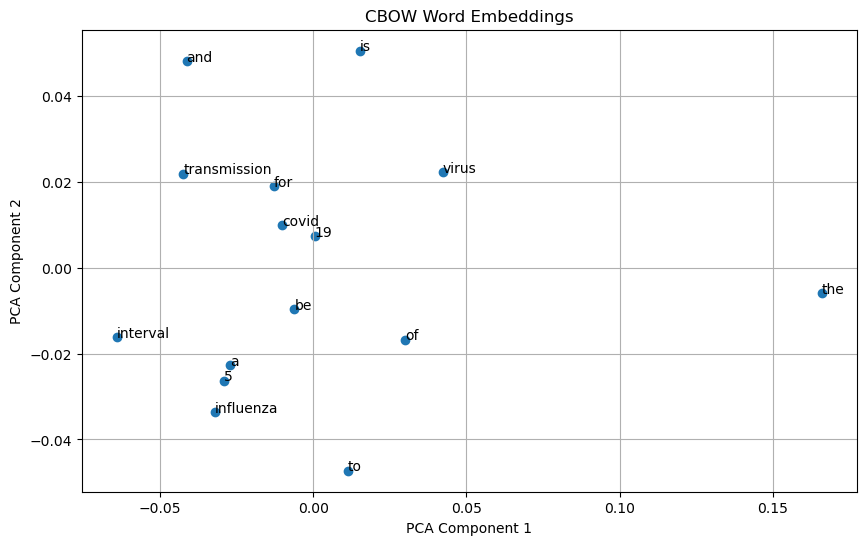

In [1]:
import re
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from sklearn.decomposition import PCA

# Step 1: Read Text File
with open("document3.txt", "r", encoding="utf-8") as file:
    text = file.read()

# Step 2: Preprocess Text
text = text.lower()

sentences = re.split(r"[.!?]+", text)

tokens = []

for sentence in sentences:
    sentence = re.sub(r"[^a-z0-9\s]", " ", sentence)
    words = sentence.split()

    if words:
        tokens.append(words)

# Step 3: Train CBOW Model
model = Word2Vec(
    sentences=tokens,
    vector_size=50,
    window=2,
    min_count=1,
    sg=0,
    epochs=100
)

print("CBOW Model Trained Successfully!")

# Step 4: Display Word Embedding
word = "virus"

print("\nWord:", word)
print("Embedding:", model.wv[word])

# Step 5: Find Similar Words
print("\nSimilar Words:")
print(model.wv.most_similar(word, topn=5))

# Step 6: Plot Word Embeddings
words = model.wv.index_to_key[:15]

vectors = [model.wv[w] for w in words]

pca = PCA(n_components=2)
result = pca.fit_transform(vectors)

plt.figure(figsize=(10, 6))
plt.scatter(result[:, 0], result[:, 1])

for i, word in enumerate(words):
    plt.annotate(word, (result[i, 0], result[i, 1]))

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("CBOW Word Embeddings")
plt.grid(True)
plt.show()